# T16. Kilómetros y energía de referencia por patinete y día

**Objetivo.** Calcular cuánta energía mueve cada viaje, cada patinete, la flota y cada zona de destino con el modelo del enunciado, `energia_wh = 13,5 × dis_m / 1000`, y una batería de 576 Wh.

**Valor para el proyecto.** Dice cada cuánto hay que recargar un patinete, el orden de magnitud de los kWh diarios por estación y qué parte de la energía llega en horas de sol. Con eso se fija la escala de la fase 3. El modelo físico es de la fase 2 y no se hace aquí.

Viajes elegibles. Las cifras que fijan parámetros salen del periodo de ajuste (1–21/02); la semana reservada se describe para compararla. Un viaje de 2 km da 27 Wh (comprobado en la celda de preparación).

In [1]:
import h3
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import patheffects
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.dates import DateFormatter
from matplotlib.patches import Patch
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

from comun.config import cargar_config, carpeta_tablas
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()
CONSUMO_WH_KM = CFG["patinete"]["consumo_wh_km"]
BATERIA_WH = CFG["patinete"]["bateria_wh"]

PARAMETROS = {
    # Caso de control del plan: un viaje de 2 km da 27 Wh.
    "control_dis_m": 2000,
    "control_energia_wh": 27.0,
    "percentiles": [5, 25, 50, 75, 95, 99],
    # Umbrales de energía por patinete y día, en % de la batería.
    "umbrales_bateria_pct": [50, 80, 100],
    # Resolución H3 de las celdas de destino (punto de partida del plan).
    "res_celdas": 8,
    "top_celdas": 20,
    # Horas de sol de referencia para el reparto horario de la energía que llega [inicio, fin).
    "horas_sol": [10, 16],
    "horas_tarde": [16, 24],
    "tolerancia_cuadre_wh": 1e-6,
}
TITULO_AJUSTE = "viajes elegibles del periodo de ajuste (1–21/02/2021)"
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
HALO = [patheffects.withStroke(linewidth=2.2, foreground="white")]
CMAP_SECUENCIAL = LinearSegmentedColormap.from_list(
    "azules", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])


def guardar_tabla(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", index=False, lineterminator="\n")


def energia_wh(dis_m):
    """Energía de tracción del modelo de referencia (Wh)."""
    return CONSUMO_WH_KM * np.asarray(dis_m, dtype=float) / 1000


def dias_periodo(nombre):
    inicio, fin = CFG["datos"]["periodos"][nombre]
    return pd.Index(pd.date_range(inicio, fin, freq="D").strftime("%Y-%m-%d"), dtype="string")


def fin_periodo(nombre):
    """Instante en que termina el periodo (medianoche del día siguiente al último)."""
    fin = CFG["datos"]["periodos"][nombre][1]
    return pd.Timestamp(fin).tz_localize(CFG["datos"]["zona_horaria"]) + pd.Timedelta(days=1)


def percentiles(x, prefijo):
    fila = {f"{prefijo}_media": x.mean()}
    for p in PARAMETROS["percentiles"]:
        fila[f"{prefijo}_p{p}"] = x.quantile(p / 100)
    fila[f"{prefijo}_max"] = x.max()
    return fila


def tabla_resumen(resumen):
    """Tabla indicador–valor con los enteros como enteros y los reales redondeados."""
    valores = [round(float(x), 3) if isinstance(x, (float, np.floating)) else int(x) for x in resumen.values()]
    return pd.DataFrame({"indicador": list(resumen), "valor": pd.Series(valores, dtype=object)})


def redondear(df, decimales=3):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]):
            df[c] = df[c].round(decimales)
    return df


# Caso de control del modelo.
assert abs(float(energia_wh(PARAMETROS["control_dis_m"])) - PARAMETROS["control_energia_wh"]) < 1e-9

v = cargar_viajes()[["trip_id", "idS", "tsO", "tsD", "latD", "lonD", "dis_m", "periodo"]].copy()
v["km"] = v["dis_m"] / 1000
v["energia_wh"] = energia_wh(v["dis_m"])
v["pct_bateria"] = 100 * v["energia_wh"] / BATERIA_WH
v["fecha"] = v["tsO"].dt.strftime("%Y-%m-%d").astype("string")
v["hora_llegada"] = v["tsD"].dt.hour
v["h3_d"] = pd.Series([h3.latlng_to_cell(a, b, PARAMETROS["res_celdas"]) for a, b in zip(v["latD"], v["lonD"])],
                      index=v.index, dtype="string")
aj = v[v["periodo"] == "ajuste"]
N_DIAS = len(dias_periodo("ajuste"))
print(f"{len(v)} viajes elegibles en el mes, {len(aj)} en el ajuste. "
      f"Control: {PARAMETROS['control_dis_m']} m dan {float(energia_wh(PARAMETROS['control_dis_m'])):.1f} Wh")

23292 viajes elegibles en el mes, 16710 en el ajuste. Control: 2000 m dan 27.0 Wh


## 1. Energía por viaje

**Qué queremos ver.** La energía de cada viaje y el porcentaje de la batería que gasta, y si algún viaje necesitaría más de una carga.

**Por qué importa.** Si un viaje pudiera gastar más que una batería, el sistema tendría que garantizar cargas completas antes de cada salida.

In [2]:
filas = []
for periodo, g in v.groupby("periodo", sort=False):
    filas.append({"periodo": periodo, "viajes": len(g), **percentiles(g["energia_wh"], "energia_wh"),
                  **percentiles(g["pct_bateria"], "pct_bateria"),
                  "viajes_mayor_bateria": int((g["energia_wh"] > BATERIA_WH).sum())})
por_viaje = redondear(pd.DataFrame(filas))
guardar_tabla(por_viaje, "T16_viaje_distribucion")
mayores = v.loc[v["energia_wh"] > BATERIA_WH, ["trip_id", "idS", "periodo", "dis_m", "energia_wh"]]
guardar_tabla(redondear(mayores.sort_values("trip_id")), "T16_viajes_mayor_bateria")

cuentas, bordes = np.histogram(aj["energia_wh"], bins=60)
exportar(FASE, "t16_viaje", {"histograma": {"bordes_wh": np.round(bordes, 3), "viajes": cuentas},
                             "tabla": por_viaje, "bateria_wh": BATERIA_WH, "consumo_wh_km": CONSUMO_WH_KM})
display(por_viaje.set_index("periodo").T)

periodo,ajuste,reservada
viajes,16710.000,6582.000
energia_wh_media,27.723,28.742
energia_wh_p5,4.703,4.805
energia_wh_p25,12.074,12.017
energia_wh_p50,21.851,22.569
energia_wh_p75,37.716,39.612
energia_wh_p95,70.013,73.510
energia_wh_p99,100.580,102.381
energia_wh_max,246.618,231.549
pct_bateria_media,4.813,4.990


**Conclusiones.**

- El viaje mediano gasta 21,9 Wh (3,8 % de la batería); el P95, 70,0 Wh (12,2 %), y el máximo, 246,6 Wh (42,8 %).
- **Ningún viaje supera los 576 Wh**: cualquier viaje cabe en una sola carga.

## 2. Energía por patinete y día

**Qué queremos ver.** Viajes, km y Wh de cada patinete en cada día con viajes, y qué parte de esos patinete-día pasa del 50, el 80 y el 100 % de la batería.

**Por qué importa.** Si un patinete gastara más de una batería en un día, habría que recargarlo dentro del día.

In [3]:
pd_dia = (v.groupby(["periodo", "idS", "fecha"], sort=True)
          .agg(viajes=("trip_id", "size"), km=("km", "sum"), energia_wh=("energia_wh", "sum"))
          .reset_index())
pd_dia["pct_bateria"] = 100 * pd_dia["energia_wh"] / BATERIA_WH
filas = []
for periodo, g in pd_dia.groupby("periodo", sort=False):
    fila = {"periodo": periodo, "patinete_dias": len(g), "viajes_media": g["viajes"].mean(),
            "viajes_max": int(g["viajes"].max()), "km_media": g["km"].mean(), "km_p95": g["km"].quantile(0.95),
            "km_max": g["km"].max(), **percentiles(g["energia_wh"], "energia_wh")}
    for u in PARAMETROS["umbrales_bateria_pct"]:
        fila[f"pct_patinete_dias_sobre_{u}pct_bateria"] = 100 * (g["pct_bateria"] > u).mean()
    filas.append(fila)
patinete_dia = redondear(pd.DataFrame(filas))
guardar_tabla(patinete_dia, "T16_patinete_dia_resumen")

cuentas, bordes = np.histogram(pd_dia.loc[pd_dia["periodo"] == "ajuste", "energia_wh"], bins=60)
exportar(FASE, "t16_patinete_dia", {"histograma": {"bordes_wh": np.round(bordes, 3), "patinete_dias": cuentas},
                                    "tabla": patinete_dia, "bateria_wh": BATERIA_WH,
                                    "umbrales_pct": PARAMETROS["umbrales_bateria_pct"]})
display(patinete_dia.set_index("periodo").T)

periodo,ajuste,reservada
patinete_dias,10220.000,4023.000
viajes_media,1.635,1.636
viajes_max,12.000,14.000
km_media,3.358,3.483
km_p95,9.102,9.426
km_max,22.084,21.693
energia_wh_media,45.327,47.025
energia_wh_p5,6.778,7.188
energia_wh_p25,17.503,18.028
energia_wh_p50,33.729,35.207


**Conclusiones.**

- Un patinete con viajes hace de media 1,6 viajes al día y gasta 45,3 Wh; el P95 es de 122,9 Wh y el máximo de 298,1 Wh.
- Solo el 0,01 % de los patinete-día pasa del 50 % de la batería y **ninguno del 80 %**: no hace falta recargar dentro del día.

## 3. Energía por patinete en el periodo

**Qué queremos ver.** Km, Wh y ciclos equivalentes (Wh / 576) de cada patinete; los días que tardaría en agotar la batería si nunca recargara, acumulando la energía por orden de `tsO`, y su autonomía (batería entre la energía media por día en servicio).

**Por qué importa.** La distribución de la autonomía da la frecuencia de recarga necesaria. Se supone la batería completa utilizable y llena en el primer viaje del periodo.

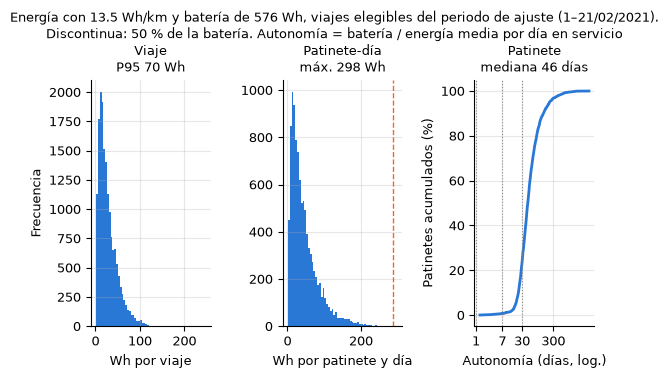

,indicador,valor
0,patinetes_mes,2305
1,patinetes_ajuste,2136
2,km_ajuste_media,16.065
3,km_ajuste_p5,2.434
4,km_ajuste_p25,8.354
5,km_ajuste_p50,14.684
6,km_ajuste_p75,22.176
7,km_ajuste_p95,34.279
8,km_ajuste_p99,44.503
9,km_ajuste_max,59.944


In [4]:
# Se supone que el patinete empieza su primer viaje del periodo con la batería llena, que
# toda la batería es utilizable y que nunca se recarga.
orden = aj.sort_values(["idS", "tsO", "trip_id"])
orden = orden.assign(acumulado_wh=orden.groupby("idS")["energia_wh"].cumsum())
primero = orden.groupby("idS")["tsO"].min()
agota = orden[orden["acumulado_wh"] >= BATERIA_WH].groupby("idS")["tsO"].min()

patinete = orden.groupby("idS").agg(viajes_ajuste=("trip_id", "size"), km_ajuste=("km", "sum"),
                                    energia_wh_ajuste=("energia_wh", "sum"))
patinete["ciclos_ajuste"] = patinete["energia_wh_ajuste"] / BATERIA_WH
patinete["dias_en_servicio"] = (fin_periodo("ajuste") - primero).dt.total_seconds() / 86400
patinete["agota_sin_recarga"] = patinete.index.isin(agota.index)
patinete["dias_hasta_agotar"] = (agota - primero).dt.total_seconds() / 86400
patinete["dias_autonomia_estimada"] = BATERIA_WH / (patinete["energia_wh_ajuste"] / patinete["dias_en_servicio"])

mes = v.groupby("idS").agg(viajes_mes=("trip_id", "size"), km_mes=("km", "sum"), energia_wh_mes=("energia_wh", "sum"))
mes["ciclos_mes"] = mes["energia_wh_mes"] / BATERIA_WH
patinete = mes.join(patinete, how="left").reset_index().sort_values("idS", ignore_index=True)
patinete["viajes_ajuste"] = patinete["viajes_ajuste"].fillna(0).astype("int64")
patinete["agota_sin_recarga"] = patinete["agota_sin_recarga"].astype("boolean").fillna(False)
guardar_tabla(redondear(patinete), "T16_patinete")

a = patinete[patinete["viajes_ajuste"] > 0]
resumen_patinete = {
    "patinetes_mes": len(patinete),
    "patinetes_ajuste": len(a),
    **percentiles(a["km_ajuste"], "km_ajuste"),
    "ciclos_ajuste_media": a["ciclos_ajuste"].mean(),
    "ciclos_ajuste_p95": a["ciclos_ajuste"].quantile(0.95),
    "ciclos_ajuste_max": a["ciclos_ajuste"].max(),
    "ciclos_mes_media": patinete["ciclos_mes"].mean(),
    "ciclos_mes_max": patinete["ciclos_mes"].max(),
    "pct_patinetes_agotan_en_ajuste": 100 * a["agota_sin_recarga"].mean(),
    "dias_hasta_agotar_p50_de_los_que_agotan": a["dias_hasta_agotar"].median(),
    "dias_autonomia_estimada_p10": a["dias_autonomia_estimada"].quantile(0.10),
    "dias_autonomia_estimada_p50": a["dias_autonomia_estimada"].quantile(0.50),
    "dias_autonomia_estimada_p90": a["dias_autonomia_estimada"].quantile(0.90),
    "pct_patinetes_autonomia_menor_1_dia": 100 * (a["dias_autonomia_estimada"] < 1).mean(),
    "pct_patinetes_autonomia_menor_7_dias": 100 * (a["dias_autonomia_estimada"] < 7).mean(),
}
resumen_patinete = tabla_resumen(resumen_patinete)
guardar_tabla(resumen_patinete, "T16_patinete_resumen")

# Figura con las tres escalas: viaje, patinete-día y patinete.
g = pd_dia[pd_dia["periodo"] == "ajuste"]
dias = np.sort(a["dias_autonomia_estimada"].to_numpy())
fig, ejes = plt.subplots(1, 3, figsize=(6.5, 3.2))
fig.subplots_adjust(wspace=0.6)
eje = ejes[0]
eje.hist(aj["energia_wh"], bins=60, color=AZUL)
eje.set_xlabel("Wh por viaje")
eje.set_ylabel("Frecuencia")
eje.set_title(f"Viaje\nP95 {aj['energia_wh'].quantile(0.95):.0f} Wh", fontsize=9)
eje = ejes[1]
eje.hist(g["energia_wh"], bins=60, color=AZUL)
for u in PARAMETROS["umbrales_bateria_pct"]:
    wh = BATERIA_WH * u / 100
    if wh <= g["energia_wh"].max() * 1.05:
        eje.axvline(wh, color=NARANJA, lw=1, ls="--")
eje.set_xlabel("Wh por patinete y día")
eje.set_title(f"Patinete-día\nmáx. {g['energia_wh'].max():.0f} Wh", fontsize=9)
eje = ejes[2]
eje.plot(dias, 100 * np.arange(1, len(dias) + 1) / len(dias), color=AZUL, lw=2)
eje.set_xscale("log")
marcas = [1, 7, 30, 300]
eje.set_xticks(marcas)
eje.set_xticklabels([str(m) for m in marcas])
eje.minorticks_off()
for d in (1, 7, 30):
    eje.axvline(d, color=GRIS, lw=0.8, ls=":")
eje.set_xlabel("Autonomía (días, log.)")
eje.set_ylabel("Patinetes acumulados (%)")
eje.set_title(f"Patinete\nmediana {np.median(dias):.0f} días", fontsize=9)
fig.suptitle(f"Energía con {CONSUMO_WH_KM} Wh/km y batería de {BATERIA_WH} Wh, {TITULO_AJUSTE}.\n"
             "Discontinua: 50 % de la batería. Autonomía = batería / energía media por día en servicio",
             fontsize=9, y=1.1)
guardar_figura(fig, TEMA, "T16_distribuciones")

exportar(FASE, "t16_patinete", {
    "autonomia_percentiles_dias": {str(q): float(np.percentile(dias, q)) for q in range(0, 101, 5)},
    "resumen": resumen_patinete,
})
display(resumen_patinete)

**Conclusiones.**

- En el ajuste, un patinete hace de media 16,1 km y 0,38 ciclos equivalentes; el máximo es de 1,405 ciclos. Solo el 1,4 % agotaría la batería sin recargar en los 21 días.
- La autonomía mediana es de 45,6 días (P10 22,8; P90 145). **Con el uso observado basta con recargar cada varios días.**
- Con estaciones y una flota simulada menor, cada patinete hará más viajes y la autonomía bajará: hay que repetir el cálculo con la flota de la fase 1.

## 4. Energía de la flota por día

**Qué queremos ver.** Km, kWh y cargas completas equivalentes (kWh / 0,576) de toda la flota cada día.

**Por qué importa.** Es la energía total que tendrán que reponer las estaciones y su variación de un día a otro.

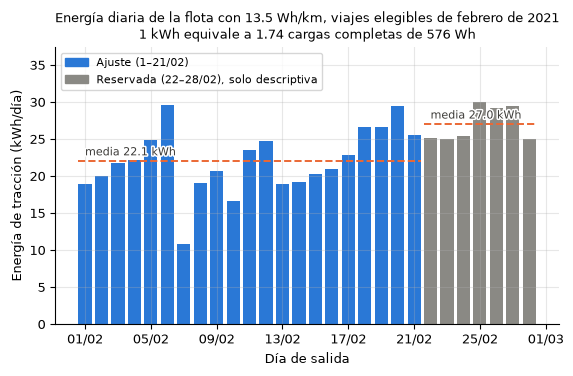

km           energia_kwh          \
                  mean       max        mean     max   
periodo                                                
ajuste     1634.018381  2188.266   22.059286  29.542   
reservada  2001.912857  2218.382   27.025857  29.948   

          cargas_completas_equivalentes          
                                   mean     max  
periodo                                          
ajuste                        38.297238  51.287  
reservada                     46.919857  51.993

In [5]:
flota = (v.groupby("fecha", sort=True)
         .agg(periodo=("periodo", "first"), viajes=("trip_id", "size"), patinetes_activos=("idS", "nunique"),
              km=("km", "sum"), energia_wh=("energia_wh", "sum"))
         .reset_index())
flota["energia_kwh"] = flota["energia_wh"] / 1000
flota["cargas_completas_equivalentes"] = flota["energia_wh"] / BATERIA_WH
flota["wh_por_patinete_activo"] = flota["energia_wh"] / flota["patinetes_activos"]
guardar_tabla(redondear(flota), "T16_flota_diaria")

fig, eje = plt.subplots(figsize=(6.5, 3.6))
x = pd.to_datetime(flota["fecha"])
eje.bar(x, flota["energia_kwh"], color=np.where(flota["periodo"] == "ajuste", AZUL, GRIS), width=0.8)
for periodo in ["ajuste", "reservada"]:
    media = flota.loc[flota["periodo"] == periodo, "energia_kwh"].mean()
    tramo = x[flota["periodo"] == periodo]
    eje.hlines(media, tramo.min() - pd.Timedelta(hours=10), tramo.max() + pd.Timedelta(hours=10),
               color=NARANJA, lw=1.4, ls="--")
    eje.annotate(f"media {media:.1f} kWh", (tramo.min(), media), xytext=(0, 4), textcoords="offset points",
                 fontsize=8, color="#3d3c39", path_effects=HALO)
eje.legend(handles=[Patch(color=AZUL, label="Ajuste (1–21/02)"),
                    Patch(color=GRIS, label="Reservada (22–28/02), solo descriptiva")], loc="upper left")
eje.set_ylim(0, flota["energia_kwh"].max() * 1.25)
eje.xaxis.set_major_formatter(DateFormatter("%d/%m"))
eje.set_xlabel("Día de salida")
eje.set_ylabel("Energía de tracción (kWh/día)")
eje.set_title(f"Energía diaria de la flota con {CONSUMO_WH_KM} Wh/km, viajes elegibles de febrero de 2021\n"
              f"1 kWh equivale a {1000 / BATERIA_WH:.2f} cargas completas de {BATERIA_WH} Wh", fontsize=9)
guardar_figura(fig, TEMA, "T16_flota_diaria")

exportar(FASE, "t16_flota_diaria", redondear(flota))
display(redondear(flota).groupby("periodo")[["km", "energia_kwh", "cargas_completas_equivalentes"]].agg(["mean", "max"]))

**Conclusiones.**

- En el ajuste, la flota recorre de media 1 634 km al día y gasta **22,1 kWh/día** (38,3 cargas completas); el máximo es de 29,5 kWh (51,3 cargas).
- En la semana reservada sube a 27,0 kWh/día, en línea con el crecimiento de la demanda (T12 y T17).

## 5. Energía por celda de destino

**Qué queremos ver.** Los kWh por día que llegan a cada celda H3 de resolución 8 y su reparto a lo largo del día, suponiendo, como el plan, que el patinete se recarga donde se deja.

**Por qué importa.** Da el orden de magnitud de la energía que tendrá que reponer cada estación y qué parte llega cuando hay sol. La que llega fuera de las horas de sol tendrá que pasar por la batería de la estación o esperar.

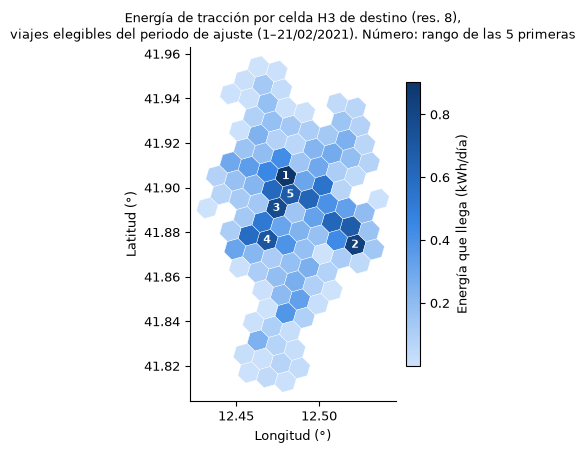

,rango,h3,llegadas,kwh_dia,cargas_completas_dia,pct_energia_10_16h,pct_energia_16_24h,pct_energia_acumulada
0,1,881e8052adfffff,571,0.902,1.566,48.081,44.006,4.089
1,2,881e805089fffff,759,0.835,1.450,32.747,63.721,7.876
2,3,881e805019fffff,549,0.776,1.346,41.437,37.833,11.392
3,4,881e805015fffff,499,0.711,1.234,37.032,52.815,14.615
4,5,881e8052a5fffff,451,0.679,1.179,34.927,35.530,17.692
5,6,881e8050c3fffff,610,0.673,1.169,26.674,61.286,20.744
6,7,881e8052a7fffff,404,0.628,1.090,27.477,62.580,23.590
7,8,881e8050c1fffff,540,0.618,1.072,25.445,62.965,26.390
8,9,881e805053fffff,432,0.603,1.047,36.704,39.153,29.123
9,10,881e805003fffff,558,0.591,1.025,22.675,69.833,31.800


In [6]:
# Se supone que el patinete se recarga donde se deja.
sol0, sol1 = PARAMETROS["horas_sol"]
tar0, tar1 = PARAMETROS["horas_tarde"]
en_sol = aj["hora_llegada"].between(sol0, sol1 - 1)
en_tarde = aj["hora_llegada"].between(tar0, tar1 - 1)
celdas = (aj.assign(wh_sol=aj["energia_wh"].where(en_sol, 0.0), wh_tarde=aj["energia_wh"].where(en_tarde, 0.0))
          .groupby("h3_d").agg(llegadas=("trip_id", "size"), energia_wh=("energia_wh", "sum"),
                               wh_sol=("wh_sol", "sum"), wh_tarde=("wh_tarde", "sum")))
celdas["kwh_dia"] = celdas["energia_wh"] / 1000 / N_DIAS
celdas["cargas_completas_dia"] = celdas["energia_wh"] / BATERIA_WH / N_DIAS
celdas[f"pct_energia_{sol0}_{sol1}h"] = 100 * celdas["wh_sol"] / celdas["energia_wh"]
celdas[f"pct_energia_{tar0}_{tar1}h"] = 100 * celdas["wh_tarde"] / celdas["energia_wh"]
celdas["pct_energia_resto"] = 100 - celdas[f"pct_energia_{sol0}_{sol1}h"] - celdas[f"pct_energia_{tar0}_{tar1}h"]
celdas["pct_energia_total"] = 100 * celdas["energia_wh"] / celdas["energia_wh"].sum()
celdas = celdas.drop(columns=["wh_sol", "wh_tarde"]).reset_index().rename(columns={"h3_d": "h3"})
celdas = celdas.sort_values(["energia_wh", "h3"], ascending=[False, True], ignore_index=True)
celdas.insert(0, "rango", np.arange(1, len(celdas) + 1))
celdas["pct_energia_acumulada"] = celdas["pct_energia_total"].cumsum()
centro = np.array([h3.cell_to_latlng(c) for c in celdas["h3"]])
celdas["lat"], celdas["lon"] = centro[:, 0].round(6), centro[:, 1].round(6)
guardar_tabla(redondear(celdas), "T16_energia_celdas")
top = redondear(celdas.head(PARAMETROS["top_celdas"]))
guardar_tabla(top, f"T16_energia_celdas_top{PARAMETROS['top_celdas']}")

fig, eje = plt.subplots(figsize=(6.5, 4.6))
polys = [np.array(h3.cell_to_boundary(c))[:, ::-1] for c in celdas["h3"]]
pc = PolyCollection(polys, array=celdas["kwh_dia"].to_numpy(), cmap=CMAP_SECUENCIAL, edgecolors="white",
                    linewidths=0.3)
eje.add_collection(pc)
puntos = np.vstack(polys)
lat0, lat1 = puntos[:, 1].min() - 0.004, puntos[:, 1].max() + 0.004
eje.set_xlim(puntos[:, 0].min() - 0.004, puntos[:, 0].max() + 0.004)
eje.set_ylim(lat0, lat1)
eje.set_aspect(1 / np.cos(np.radians((lat0 + lat1) / 2)))
eje.grid(False)
eje.xaxis.set_major_locator(MaxNLocator(3))
eje.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
eje.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
for _, fila in celdas.head(5).iterrows():
    eje.annotate(str(fila["rango"]), (fila["lon"], fila["lat"]), ha="center", va="center", fontsize=8,
                 color="white", fontweight="bold")
eje.set_xlabel("Longitud (°)")
eje.set_ylabel("Latitud (°)")
fig.colorbar(pc, ax=eje, shrink=0.8, pad=0.02).set_label("Energía que llega (kWh/día)")
eje.set_title(f"Energía de tracción por celda H3 de destino (res. {PARAMETROS['res_celdas']}),\n"
              f"{TITULO_AJUSTE}. Número: rango de las 5 primeras", fontsize=9)
guardar_figura(fig, TEMA, "T16_energia_celdas")

exportar(FASE, "t16_celdas", {
    "res": PARAMETROS["res_celdas"],
    "celdas": [{"h3": c, "rango": int(r), "kwh_dia": round(float(k), 4), "contorno": np.round(p, 5).tolist()}
               for c, r, k, p in zip(celdas["h3"], celdas["rango"], celdas["kwh_dia"], polys)],
})
display(top[["rango", "h3", "llegadas", "kwh_dia", "cargas_completas_dia", f"pct_energia_{sol0}_{sol1}h",
             f"pct_energia_{tar0}_{tar1}h", "pct_energia_acumulada"]].head(10))

**Conclusiones.**

- La celda que más energía recibe llega a **0,90 kWh/día** (1,6 cargas completas); la mediana de las celdas es de 0,13 kWh/día. Una estación, que cubrirá menos área que una celda de resolución 8, estará entre décimas de kWh y 1 kWh al día.
- 47 de las 111 celdas reúnen el 80 % de la energía.

## 6. Perfil horario de la energía que llega

**Qué queremos ver.** La energía que llega a destino en cada hora del día y la parte que llega entre las 10 y las 16 h frente a la que llega de 16 a 24 h.

**Por qué importa.** Si la recarga empieza al llegar, la energía que llega sin sol tendrá que salir de la batería de la estación: es una primera medida de cuánto tendrá que trabajar.

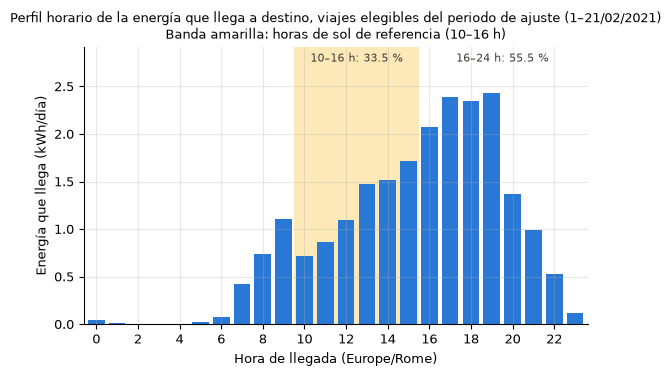

,pct_energia
pct_energia_llega_10_16h,33.53
pct_energia_llega_16_24h,55.45
pct_energia_llega_resto,11.02


In [7]:
perfil = (aj.groupby("hora_llegada")["energia_wh"].agg(["size", "sum"])
          .reindex(range(24), fill_value=0).rename(columns={"size": "llegadas", "sum": "energia_wh"}))
perfil.index.name = "hora"
perfil["energia_wh_dia"] = perfil["energia_wh"] / N_DIAS
perfil["pct_energia"] = 100 * perfil["energia_wh"] / perfil["energia_wh"].sum()
perfil = perfil.reset_index()
guardar_tabla(redondear(perfil), "T16_perfil_horario")

pct_sol = perfil.loc[perfil["hora"].between(sol0, sol1 - 1), "pct_energia"].sum()
pct_tarde = perfil.loc[perfil["hora"].between(tar0, tar1 - 1), "pct_energia"].sum()
reparto = {f"pct_energia_llega_{sol0}_{sol1}h": pct_sol, f"pct_energia_llega_{tar0}_{tar1}h": pct_tarde,
           "pct_energia_llega_resto": 100 - pct_sol - pct_tarde}

fig, eje = plt.subplots(figsize=(6.5, 3.6))
eje.axvspan(sol0 - 0.5, sol1 - 0.5, color="#fde9b8", zorder=0, lw=0)
eje.bar(perfil["hora"], perfil["energia_wh_dia"] / 1000, color=AZUL, width=0.8)
for h0, h1, pct in [(sol0, sol1, pct_sol), (tar0, tar1, pct_tarde)]:
    eje.annotate(f"{h0}–{h1} h: {pct:.1f} %", ((h0 + h1) / 2 - 0.5, 1), xycoords=("data", "axes fraction"),
                 xytext=(0, -4), textcoords="offset points", ha="center", va="top", fontsize=8, color="#3d3c39")
eje.set_xticks(range(0, 24, 2))
eje.set_xlim(-0.6, 23.6)
eje.set_ylim(0, perfil["energia_wh_dia"].max() / 1000 * 1.2)
eje.set_xlabel("Hora de llegada (Europe/Rome)")
eje.set_ylabel("Energía que llega (kWh/día)")
eje.set_title(f"Perfil horario de la energía que llega a destino, {TITULO_AJUSTE}\n"
              f"Banda amarilla: horas de sol de referencia ({sol0}–{sol1} h)", fontsize=9)
guardar_figura(fig, TEMA, "T16_perfil_horario")

exportar(FASE, "t16_perfil_horario", {"horas": redondear(perfil), "reparto_pct": reparto,
                                      "horas_sol": PARAMETROS["horas_sol"]})
display(pd.Series(reparto).round(2).to_frame("pct_energia"))

**Conclusiones.**

- El 33,53 % de la energía llega de 10 a 16 h, el 55,45 % de 16 a 24 h y el 11,02 % el resto del día.
- Con carga inmediata, la batería de la estación tendría que guardar unos dos tercios de la energía. La carga inteligente (aplazar la recarga a las horas de sol) es la alternativa que se estudiará en la fase 3.

## 7. Comprobación

**Qué queremos ver.** Que la energía sumada por viaje coincide con la sumada por patinete, por patinete y día, por día de la flota y por celda de destino, y el caso de control de 2 km.

**Por qué importa.** Las agregaciones de la fase 2 y la fase 3 se apoyarán en estas mismas sumas.

In [8]:
p = PARAMETROS
control = float(energia_wh(p["control_dis_m"]))
base_aj, base_mes = aj["energia_wh"].sum(), v["energia_wh"].sum()
filas = [
    ("control_2km", control, p["control_energia_wh"]),
    ("ajuste_patinete", patinete["energia_wh_ajuste"].sum(), base_aj),
    ("ajuste_patinete_dia", pd_dia.loc[pd_dia["periodo"] == "ajuste", "energia_wh"].sum(), base_aj),
    ("ajuste_flota_dia", flota.loc[flota["periodo"] == "ajuste", "energia_wh"].sum(), base_aj),
    ("ajuste_celda_destino", celdas["energia_wh"].sum(), base_aj),
    ("mes_patinete", patinete["energia_wh_mes"].sum(), base_mes),
    ("mes_patinete_dia", pd_dia["energia_wh"].sum(), base_mes),
    ("mes_flota_dia", flota["energia_wh"].sum(), base_mes),
]
comprobacion = pd.DataFrame(filas, columns=["agregado", "energia_wh", "referencia_wh"])
comprobacion["diferencia_wh"] = (comprobacion["energia_wh"] - comprobacion["referencia_wh"]).abs()
comprobacion["cuadra"] = comprobacion["diferencia_wh"] < p["tolerancia_cuadre_wh"]
assert comprobacion["cuadra"].all(), comprobacion
comprobacion[["energia_wh", "referencia_wh"]] = comprobacion[["energia_wh", "referencia_wh"]].round(3)
comprobacion["diferencia_wh"] = comprobacion["diferencia_wh"].round(6)
guardar_tabla(comprobacion, "T16_comprobacion")
display(comprobacion)

,agregado,energia_wh,referencia_wh,diferencia_wh,cuadra
0,control_2km,27.000,27.000,0.0,True
1,ajuste_patinete,463244.235,463244.235,0.0,True
2,ajuste_patinete_dia,463244.235,463244.235,0.0,True
3,ajuste_flota_dia,463244.235,463244.235,0.0,True
4,ajuste_celda_destino,463244.235,463244.235,0.0,True
5,mes_patinete,652425.006,652425.006,0.0,True
6,mes_patinete_dia,652425.006,652425.006,0.0,True
7,mes_flota_dia,652425.006,652425.006,0.0,True


**Conclusiones.**

- Todas las sumas cuadran con diferencia 0 Wh (tolerancia de 1e-6 Wh) y el viaje de 2 km da 27 Wh.

## 8. Tabla de indicadores

**Qué queremos ver.** Los indicadores de flota, celdas y reparto horario en una tabla.

**Por qué importa.** Es la tabla que citan `docs/conclusiones_eda.md` y la memoria.

In [9]:
fa = flota[flota["periodo"] == "ajuste"]
fr = flota[flota["periodo"] == "reservada"]
resumen = tabla_resumen({
    "consumo_wh_km": CONSUMO_WH_KM,
    "bateria_wh": BATERIA_WH,
    "flota_km_dia_media_ajuste": fa["km"].mean(),
    "flota_kwh_dia_media_ajuste": fa["energia_kwh"].mean(),
    "flota_kwh_dia_max_ajuste": fa["energia_kwh"].max(),
    "flota_cargas_dia_media_ajuste": fa["cargas_completas_equivalentes"].mean(),
    "flota_cargas_dia_max_ajuste": fa["cargas_completas_equivalentes"].max(),
    "flota_kwh_dia_media_reservada": fr["energia_kwh"].mean(),
    "flota_kwh_total_ajuste": fa["energia_kwh"].sum(),
    "celdas_destino_ajuste": len(celdas),
    "celda_kwh_dia_max": celdas["kwh_dia"].max(),
    "celda_kwh_dia_p50": celdas["kwh_dia"].median(),
    "celdas_80pct_energia": int((celdas["pct_energia_acumulada"] < 80).sum() + 1),
    **reparto,
})
guardar_tabla(resumen, "T16_resumen")
exportar(FASE, "t16_resumen", resumen)
display(resumen)

,indicador,valor
0,consumo_wh_km,13.5
1,bateria_wh,576
2,flota_km_dia_media_ajuste,1634.018
3,flota_kwh_dia_media_ajuste,22.059
4,flota_kwh_dia_max_ajuste,29.542
5,flota_cargas_dia_media_ajuste,38.297
6,flota_cargas_dia_max_ajuste,51.287
7,flota_kwh_dia_media_reservada,27.026
8,flota_kwh_total_ajuste,463.244
9,celdas_destino_ajuste,111


## Decisiones

| Decisión | Valor |
|---|---|
| Frecuencia de recarga | Cada varios días con el uso observado (autonomía mediana de 45,6 días); repetir con la flota simulada |
| Energía por estación | De décimas de kWh a 1 kWh al día |
| Energía en horas de sol | Un tercio llega de 10 a 16 h; más de la mitad de 16 a 24 h |

El detalle de cada decisión está en `docs/conclusiones_eda.md`.